# Week 2, lab A: Which catchment attributes matter? Regularization on CAMELS

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cdds-uiuc/applied-ai-earth-sciences/blob/main/week02_regression_regularization/W02_labA_camels_lasso.ipynb)

## The question

Week 1's 27-feature linear regression predicted mean streamflow from catchment attributes. Two questions were left open. First, would a more flexible model do better, and if so, by how much before it starts to overfit? Second, the coefficient plot suggested that a few climate attributes do most of the work; can we make the model *say* which attributes matter, instead of reading it off a bar chart? Ridge and Lasso answer both: Ridge lets us use a much more flexible model safely, and Lasso selects features. Then we ask a hydrologist's question: does the data-driven selection agree with what we know about how catchments work?

> **Data card.** *CAMELS catchment attributes (version 2.0).* Source: Addor et al. (2017); attribute files `camels_attributes_v2.0` (DOI 10.5065/D6G73C3Q), Zenodo record 15529996 (record version 1.2, which also carries the time series, DOI 10.5065/D6MW2F4D). License: CC BY 4.0; redistribution permitted with attribution. What: static attributes for 671 US catchments; features = the 27 attributes of Kratzert et al. (2019), with units as tabulated in the Week 1 lab; target = `q_mean`, mean daily streamflow in mm/day. Size: 0.6 MB, seven text files. Coverage: CONUS; climate and flow attributes are water-year 1990–2009 means, vegetation 2002–2014, soils and geology static. Pre-processing by instructor: none. Citation: Addor et al. (2017), *HESS* 21, 5293–5313; Kratzert et al. (2019), *HESS* 23, 5089–5110.


In [1]:
# --- Setup: all imports, the seed, plot settings. The same block opens every notebook in this course. ---
import os
import random
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

seed = 42                      # one seed for the whole notebook; re-set it before any cell you re-run
random.seed(seed)
np.random.seed(seed)

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["font.size"] = 12
# Okabe–Ito: eight colorblind-safe colors as the default color cycle
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#E69F00", "#56B4E9", "#009E73", "#F0E442",
                                                     "#0072B2", "#D55E00", "#CC79A7", "#000000"])


## Get the data

> **AI assistant: good use here.** The next three cells are the same boilerplate as Week 1.


In [2]:
data_dir = "data"                       # created next to this notebook; ignored by git
os.makedirs(data_dir, exist_ok=True)

base_url = "https://zenodo.org/records/15529996/files/"
attribute_files = ["camels_clim", "camels_geol", "camels_hydro", "camels_name",
                   "camels_soil", "camels_topo", "camels_vege"]

for name in attribute_files:
    fname = os.path.join(data_dir, name + ".txt")
    if not os.path.exists(fname):       # download once; a hand-placed file is simply used
        print("downloading", name)
        urllib.request.urlretrieve(base_url + name + ".txt?download=1", fname)
print("all seven attribute files are in", data_dir)


all seven attribute files are in data


In [3]:
# The seven files share the column gauge_id. Read each one and join them side by side.
tables = []
for name in attribute_files:
    table = pd.read_csv(os.path.join(data_dir, name + ".txt"), sep=";", dtype={"gauge_id": str})
    tables.append(table.set_index("gauge_id"))
camels = pd.concat(tables, axis=1)      # one row per catchment, every attribute as a column
print(camels.shape)                     # (n_catchments, n_columns)


(671, 59)


In [4]:
# The 27 static attributes used by Kratzert et al. (2019). None is computed from streamflow, which matters:
# anything derived from the target (q_mean, runoff_ratio, baseflow_index, ...) would be cheating.
# (One subtlety: CAMELS' potential evaporation uses a Priestley-Taylor coefficient calibrated per catchment inside
# a rainfall-runoff model (Newman et al., 2015), so pet_mean and aridity are not purely meteorological.)
feature_names = [
    "p_mean", "pet_mean", "aridity", "p_seasonality", "frac_snow",
    "high_prec_freq", "high_prec_dur", "low_prec_freq", "low_prec_dur",
    "elev_mean", "slope_mean", "area_gages2",
    "frac_forest", "lai_max", "lai_diff", "gvf_max", "gvf_diff",
    "soil_depth_pelletier", "soil_depth_statsgo", "soil_porosity", "soil_conductivity",
    "max_water_content", "sand_frac", "silt_frac", "clay_frac",
    "carbonate_rocks_frac", "geol_permeability",
]
target_name = "q_mean"                  # mean daily streamflow, mm/day

catchments = camels.dropna(subset=feature_names + [target_name])

def rmse(y: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.sqrt(np.mean((y - y_pred) ** 2)))

print(len(catchments), "catchments with every feature and the target")


670 catchments with every feature and the target


## Look at the data

The same table as Week 1, so a short look: the target's range and distribution, and a check that nothing is missing.


count    670.00
mean       1.49
std        1.54
min        0.00
25%        0.63
50%        1.13
75%        1.75
max        9.69
Name: q_mean, dtype: float64
missing values among the features and target: 0


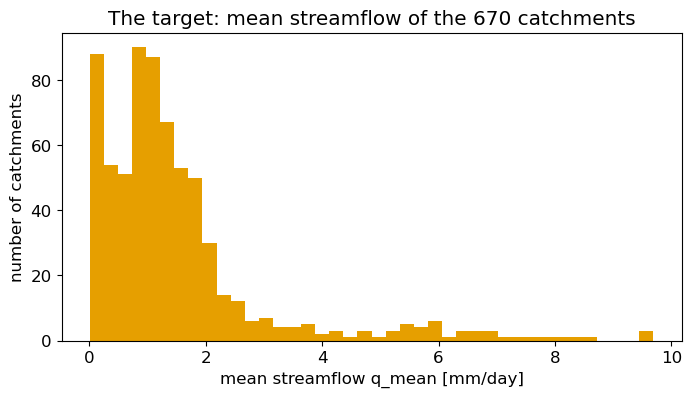

In [5]:
print(catchments[target_name].describe().round(2))
print("missing values among the features and target:", int(catchments[feature_names + [target_name]].isna().sum().sum()))

fig, ax = plt.subplots()
ax.hist(catchments[target_name], bins=40)
ax.set_xlabel("mean streamflow q_mean [mm/day]")
ax.set_ylabel("number of catchments")
ax.set_title("The target: mean streamflow of the 670 catchments")
plt.show()


A right-skewed distribution: two thirds of the catchments have between 0.5 and 2.5 mm/day, the median is 1.1, and a thin tail of Pacific Northwest catchments reaches almost 10 mm/day. The baseline (predict the mean) has to cover that whole spread with one number, which is why its RMSE is so large.


## Three splits, not two

This week we choose a model setting (alpha) on data the model did not see, *and* we want an honest final number. That needs three sets: **training** (fit the coefficients), **validation** (choose alpha), **test** (report once, at the end). We split 60/20/20 and standardize with the training set's means and standard deviations.


In [6]:
X = catchments[feature_names].values                 # (n_catchments, 27)
y = catchments[target_name].values                   # (n_catchments,)

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, random_state=seed)
print(X_train.shape, X_val.shape, X_test.shape)

scaler = StandardScaler().fit(X_train)               # means and standard deviations from the training set only
X_train_std = scaler.transform(X_train)
X_val_std = scaler.transform(X_val)
X_test_std = scaler.transform(X_test)


(402, 27) (134, 27) (134, 27)


In [7]:
rmse_baseline = rmse(y_test, np.full_like(y_test, y_train.mean()))
ols = LinearRegression().fit(X_train_std, y_train)
rmse_ols = rmse(y_test, ols.predict(X_test_std))
print(f"baseline (mean) test RMSE: {rmse_baseline:.3f} mm/day")
print(f"OLS, 27 features test RMSE: {rmse_ols:.3f} mm/day")


baseline (mean) test RMSE: 1.317 mm/day
OLS, 27 features test RMSE: 0.348 mm/day


## A more flexible model: every product of two attributes

The straight-line model cannot express interactions: "snow matters more in high catchments", "aridity matters more where soils are thin". A cheap way to let it is to add every product of two features (and every square) as new features: 27 original + 27 squares + 351 pairwise products = 405 features. That is a very flexible linear model, and with about 400 training catchments it is a recipe for overfitting.

> **Write this yourself.** From here to the evaluation is the modeling core of the week: the cells the homework asks you to write yourself, without an assistant. In the lab they are worked for you; read them as if you were about to write them.


In [8]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_std)                    # (n_train, 405)
X_val_poly = poly.transform(X_val_std)
X_test_poly = poly.transform(X_test_std)
print(X_train_poly.shape)

ols_poly = LinearRegression().fit(X_train_poly, y_train)
print(f"OLS on 405 polynomial features:   train RMSE {rmse(y_train, ols_poly.predict(X_train_poly)):.3f}   "
      f"validation RMSE {rmse(y_val, ols_poly.predict(X_val_poly)):.3f} mm/day")


(402, 405)
OLS on 405 polynomial features:   train RMSE 0.000   validation RMSE 3.172 mm/day


The training error is exactly zero: with 405 features and only 402 training catchments the model has more parameters than data points and passes through every training point, the same interpolation that core 2 showed with 49 points and 50 features. The validation error is far worse than the plain 27-feature model's: textbook overfitting, Week 2 core 1 on real data. Now the same 405 features with Ridge, choosing alpha on the validation set.

(One shortcut to be aware of: the products of standardized features are not themselves standardized; their spreads range from about 0.5 to 9. Re-standardizing the 405 columns changes the Ridge result below by about 0.01 mm/day, so we keep the simpler pipeline here, but "standardize before regularizing" is the rule and this is a knowing exception.)


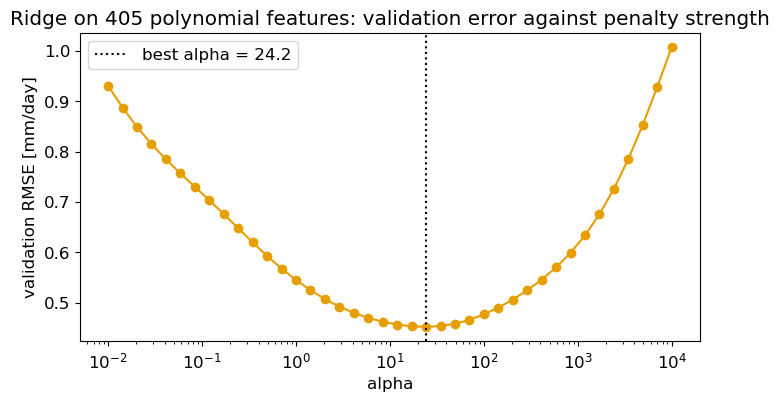

In [9]:
alphas = np.logspace(-2, 4, 40)
val_rmse = []
for alpha in alphas:
    ridge = Ridge(alpha=alpha).fit(X_train_poly, y_train)
    val_rmse.append(rmse(y_val, ridge.predict(X_val_poly)))
best_alpha_ridge = alphas[int(np.argmin(val_rmse))]

fig, ax = plt.subplots()
ax.plot(alphas, val_rmse, "o-")
ax.axvline(best_alpha_ridge, color="black", linestyle=":", label=f"best alpha = {best_alpha_ridge:.3g}")
ax.set_xscale("log")
ax.set_xlabel("alpha")
ax.set_ylabel("validation RMSE [mm/day]")
ax.set_title("Ridge on 405 polynomial features: validation error against penalty strength")
ax.legend()
plt.show()


Validation error is large at very small alpha (almost OLS: overfitting), falls to a minimum, and rises again at very large alpha (everything shrunk toward the mean: underfitting). The best alpha sits in between, and the resulting model is tested once.


In [10]:
ridge_poly = Ridge(alpha=best_alpha_ridge).fit(X_train_poly, y_train)
rmse_ridge_poly = rmse(y_test, ridge_poly.predict(X_test_poly))
print(f"Ridge, 405 features, alpha {best_alpha_ridge:.3g}:  test RMSE {rmse_ridge_poly:.3f} mm/day")


Ridge, 405 features, alpha 24.2:  test RMSE 0.338 mm/day


## Lasso on the 27 attributes: let the model choose

Now the second question. Lasso on the original 27 standardized attributes, with alpha swept over a wide range, gives a path of coefficients and a validation curve.


In [11]:
alphas_lasso = np.logspace(-3, 0, 40)
lasso_paths = np.zeros((len(alphas_lasso), len(feature_names)))
val_rmse_lasso = []
for i, alpha in enumerate(alphas_lasso):
    lasso = Lasso(alpha=alpha, max_iter=50000).fit(X_train_std, y_train)     # max_iter raised so the solver converges at small alpha
    lasso_paths[i] = lasso.coef_
    val_rmse_lasso.append(rmse(y_val, lasso.predict(X_val_std)))
val_rmse_lasso = np.array(val_rmse_lasso)

best_alpha_lasso = alphas_lasso[int(np.argmin(val_rmse_lasso))]
print(f"alpha with the lowest validation RMSE: {best_alpha_lasso:.3g}  "
      f"(keeps {int((lasso_paths[int(np.argmin(val_rmse_lasso))] != 0).sum())} of 27 attributes)")


alpha with the lowest validation RMSE: 0.001  (keeps 26 of 27 attributes)


With 400 training catchments and only 27 attributes there is not much overfitting to cure, so the validation curve is nearly flat over a wide range of alpha, and its minimum sits at the smallest alpha in our grid, a penalty so tiny that it keeps almost every attribute (a smaller alpha still would do no better: the curve is flat all the way down to plain OLS). That is a real finding, not a failure: many models are equally good on the validation set. When that happens, the sensible choice is the **simplest model that is nearly as good as the best**. We take the largest alpha whose validation RMSE is within 5 % of the minimum. (Statisticians call a close cousin of this the one-standard-error rule.)


largest alpha within 5 % of the best validation RMSE: 0.017


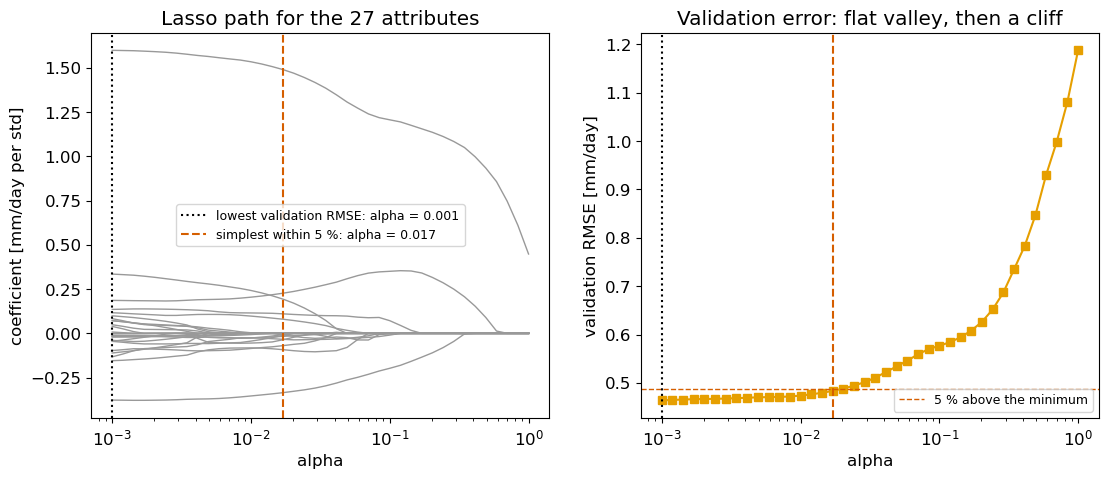

In [12]:
tolerance = 1.05 * val_rmse_lasso.min()                                   # "within 5 % of the best"
alpha_parsimonious = alphas_lasso[val_rmse_lasso <= tolerance].max()          # the largest alpha that qualifies
print(f"largest alpha within 5 % of the best validation RMSE: {alpha_parsimonious:.3g}")

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(13, 5))
for j, name in enumerate(feature_names):
    ax_left.plot(alphas_lasso, lasso_paths[:, j], color="#999999", linewidth=1)
ax_left.axvline(best_alpha_lasso, color="black", linestyle=":", label=f"lowest validation RMSE: alpha = {best_alpha_lasso:.3g}")
ax_left.axvline(alpha_parsimonious, color="#D55E00", linestyle="--", label=f"simplest within 5 %: alpha = {alpha_parsimonious:.3g}")
ax_left.set_xscale("log")
ax_left.set_xlabel("alpha")
ax_left.set_ylabel("coefficient [mm/day per std]")
ax_left.set_title("Lasso path for the 27 attributes")
ax_left.legend(fontsize=9)

ax_right.plot(alphas_lasso, val_rmse_lasso, "s-")
ax_right.axhline(tolerance, color="#D55E00", linestyle="--", linewidth=1, label="5 % above the minimum")
ax_right.axvline(best_alpha_lasso, color="black", linestyle=":")
ax_right.axvline(alpha_parsimonious, color="#D55E00", linestyle="--")
ax_right.set_xscale("log")
ax_right.set_xlabel("alpha")
ax_right.set_ylabel("validation RMSE [mm/day]")
ax_right.set_title("Validation error: flat valley, then a cliff")
ax_right.legend(fontsize=9)
plt.show()


Left: as alpha grows, attribute coefficients drop to zero one after another; the one line far above the rest is `p_mean`; the dotted line marks the validation minimum and the dashed line the parsimonious choice. Right: the validation RMSE is flat across the valley and climbs steeply once alpha removes attributes the model needs.


Lasso, parsimonious alpha 0.017: 14 of 27 attributes kept;  test RMSE 0.342 mm/day


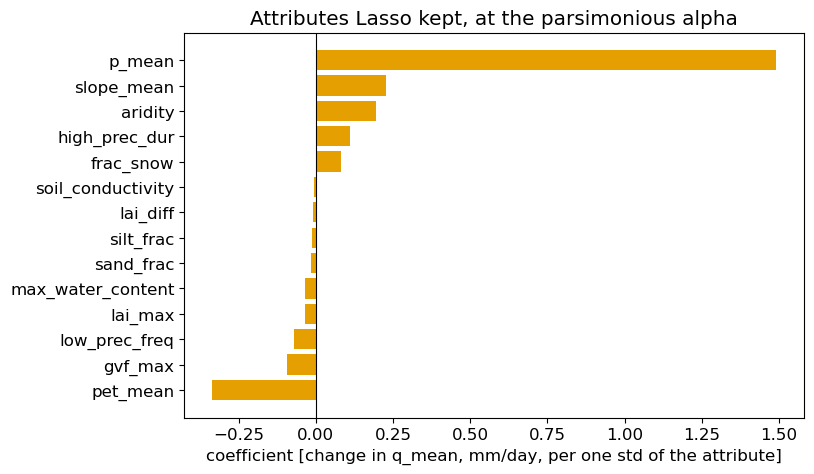

In [13]:
lasso_best = Lasso(alpha=alpha_parsimonious, max_iter=50000).fit(X_train_std, y_train)
rmse_lasso = rmse(y_test, lasso_best.predict(X_test_std))

kept = pd.Series(lasso_best.coef_, index=feature_names)
kept = kept[kept != 0].sort_values()
print(f"Lasso, parsimonious alpha {alpha_parsimonious:.3g}: {len(kept)} of 27 attributes kept;  test RMSE {rmse_lasso:.3f} mm/day")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(kept.index, kept.values)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("coefficient [change in q_mean, mm/day, per one std of the attribute]")
ax.set_title("Attributes Lasso kept, at the parsimonious alpha")
plt.show()


`p_mean` dominates, as in Week 1; `slope_mean`, aridity, `high_prec_dur` and `frac_snow` are the positive supporting cast; `pet_mean` is the one large negative; the vegetation and soil attributes that survive have small coefficients (the soil ones at most 2 % of `p_mean`'s); and no geology attribute survives. The surviving list is the model's own statement of what matters for mean flow.

## Evaluation


In [14]:
print(f"baseline (training mean):       {rmse_baseline:.3f} mm/day")
print(f"OLS, 27 attributes:             {rmse_ols:.3f} mm/day")
print(f"Ridge, 405 polynomial features: {rmse_ridge_poly:.3f} mm/day")
print(f"Lasso, {len(kept):2d} attributes kept:        {rmse_lasso:.3f} mm/day")


baseline (training mean):       1.317 mm/day
OLS, 27 attributes:             0.348 mm/day
Ridge, 405 polynomial features: 0.338 mm/day
Lasso, 14 attributes kept:        0.342 mm/day


## Interpretation

Three findings, in the language of the problem.

First, flexibility bought little. The 405-feature Ridge model, which can express every pairwise interaction between attributes, improves on the 27-feature straight line only modestly, if at all; the interactions a hydrologist might expect (snow × elevation, aridity × soil depth) are either weak at the scale of long-term mean flow or already captured by the climate attributes. Without regularization that same flexible model was useless, so Ridge is what made the experiment possible.

Second, Lasso's shorter list (14 of the 27 attributes) reads like a hydrologist's own: precipitation first; then potential evaporation, aridity, snow fraction and slope as the supporting cast. Geology drops out and the soil attributes keep only small coefficients: what governs *how* water moves through a catchment barely registers for *how much* leaves it on average over decades. That is what the Budyko framework predicts: the long-term partitioning of precipitation into flow and evapotranspiration is set by water supply (precipitation) and atmospheric demand (potential evaporation), with landscape properties a second-order modulation. Reaching that list took a judgment call: the validation curve was flat, so we chose the simplest model within 5 % of the best rather than the literal minimum. Model selection is rarely a single number. This agreement between a data-driven selection and physical reasoning is a form of validation that no error metric provides, and it is what the course means by evaluating a model with domain knowledge.

Third, all three models land within a narrow band of test RMSE, about a quarter of the baseline's (0.34 against 1.32 mm/day). The remaining error is not a matter of model choice; it is the information that 27 long-term averages cannot contain, and the time series of Week 9 will be the next place to look.

> **Warning.** The test catchments are random neighbors of the training catchments, so these RMSEs are optimistic; Week 3's spatial cross-validation shows by how much.

## Exercises

Labs are graded on completion: run every cell and attempt each exercise, leaving your result in the cell provided. Keep `random_state=seed` in any split you make, so that your numbers are comparable with a classmate's; solutions to the lab exercises are released at the homework deadline.

> **Exercise.** Multiply the parsimonious alpha by 3 and refit. Which attributes survive now, and what happened to the test RMSE?


In [15]:
# Exercise 1: work here
np.random.seed(seed)


*One sentence on what you found:*


> **Exercise.** Run Lasso on the 405 polynomial features (`X_train_poly`, with the parsimonious alpha chosen on `X_val_poly`; use `max_iter=50000`, and expect the sweep to take a few seconds). How many of the 405 terms survive, how many of them are products or squares, and does the test RMSE beat the Ridge-405 model's? Hint: `poly.get_feature_names_out(feature_names)` names the 405 columns.


In [16]:
# Exercise 2: work here
np.random.seed(seed)


*One sentence on what you found:*


> **Exercise.** Change the target to `runoff_ratio` (flow divided by precipitation, already a column of `catchments`) and repeat the Lasso selection. Does precipitation still dominate, and which attributes gain?


In [17]:
# Exercise 3: work here
np.random.seed(seed)


*One sentence on what you found:*


> **Exercise.** This week's AI-assistant thread is debugging. In the Lasso sweep cell, change `max_iter=50000` to `max_iter=100` and re-run it: scikit-learn prints a `ConvergenceWarning`. Paste the warning and the cell into your assistant and ask what the warning means and how to fix it. Check its answer against the notebook: did it suggest raising `max_iter`, changing `alpha`, standardizing (already done), or something else, and which suggestions were right? Put `max_iter` back afterwards and re-run the cell.

> **AI assistant: good use here.** Explaining an error or warning message is exactly what the policy allows; checking the explanation against what the code actually does is your part.


*One sentence on what the assistant got right and what it got wrong:*
